#### Oversampling
Using SDV Framework

CTGAN

In [19]:
from sdv.single_table import CTGANSynthesizer
import pandas as pd
from sdv.metadata import Metadata


# Loading the dataset
df = pd.read_csv("../../laptopprice_dataset_cleaned.csv")


# CTGAN is fairly slow to train
# so reduce columns / rows to speed it up if you want
# this housing dataset: 21.5k houses with 16 columns => 13-16 minutes to fit CTGAN
# df = df.sample(2000)

# Create metadata using a dictionary
metadata = Metadata.detect_from_dataframes(data={"laptops": df})


# Set the model and fit.
model = CTGANSynthesizer(metadata)
model.fit({"laptops": df})

c:\Users\Gayani\Advanced Data Analytics\AdvancedDataAnalytics\.venv\Lib\site-packages\sdv\single_table\base.py:136: UserWarning: We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.
  warnings.warn(


In [ ]:
# Check the installed SDV version (2.2.0)
import sdv
print("SDV version:", sdv.__version__)

SDV version: 2.2.0


In [21]:
# Create 5k rows.
synthetic_data = model.sample(num_rows=5000)

#### Using SDV evaluate Quality

In [ ]:
# Let's use the evaluate_quality function in SDV's library
from sdv.evaluation import evaluate_quality
synthetic_df = synthetic_data["laptops"]   # use the table name you gave the metadata

quality_report = evaluate_quality(
    real_data=df,
    synthetic_data=synthetic_df,
    metadata=metadata,
)


# The higher the percentile, the better the fit. 
quality_report

# Column shapes (94.94%): each column's distribution, real vs synthetic.
# Column pair trends (81.22%): relationships between pairs of columns.
# Overall score 88.08% = good range (80-95%).
# As with the Gaussian Copula, pair trends score is lower than column shapes,
# so relationships between columns are harder to reproduce than single columns.

Generating report ...

(1/4) Evaluating Column Shapes: |██████████| 44/44 [00:00<00:00, 688.51it/s]|
Column Shapes Score: 94.94%

(2/4) Evaluating Column Pair Trends: |██████████| 946/946 [00:01<00:00, 711.47it/s]|
Column Pair Trends Score: 81.22%

(3/4) Evaluating Cardinality: N/A
This property does not apply to single-table data.

(4/4) Evaluating Intertable Trends: N/A
This property does not apply to single-table data.

Overall Score (Average): 88.08%



In [23]:
import sdv.evaluation as ev
print(dir(ev))

['__all__', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__path__', '__spec__', '_visualization', 'evaluate_quality', 'evaluation', 'get_cardinality_plot', 'get_column_pair_plot', 'get_column_plot', 'run_diagnostic']


In [24]:
# switching to decimal notation for the variance checks
pd.set_option('display.float_format', lambda x: "%.2f" % x)

In [25]:
# We can compare the statistics between the two dataframes by using `.describe()`
df.describe()

,Ram,Weight,Price,TouchScreen,Ips,Ppi,HDD,SSD,Company_Acer,Company_Apple,...,Cpu_brand_Intel Core i3,Cpu_brand_Intel Core i5,Cpu_brand_Intel Core i7,Cpu_brand_Other Intel Processor,Gpu_brand_AMD,Gpu_brand_Intel,Gpu_brand_Nvidia,Os_Mac,Os_Others,Os_Windows
count,1273.00,1273.00,1273.00,1273.00,1273.00,1273.00,1273.00,1273.00,1273.00,1273.00,...,1273.00,1273.00,1273.00,1273.00,1273.00,1273.00,1273.00,1273.00,1273.00,1273.00
mean,8.45,2.04,10.83,0.15,0.28,146.95,413.72,186.25,0.08,0.02,...,0.11,0.33,0.40,0.11,0.14,0.55,0.31,0.02,0.12,0.86
std,5.10,0.67,0.62,0.35,0.45,42.93,518.05,186.53,0.27,0.13,...,0.31,0.47,0.49,0.31,0.34,0.50,0.46,0.13,0.32,0.34
min,2.00,0.69,9.13,0.00,0.00,90.58,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,4.00,1.50,10.39,0.00,0.00,127.34,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00
50%,8.00,2.04,10.87,0.00,0.00,141.21,0.00,256.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,1.00
75%,8.00,2.31,11.29,0.00,1.00,157.35,1000.00,256.00,0.00,0.00,...,0.00,1.00,1.00,0.00,0.00,1.00,1.00,0.00,0.00,1.00
max,64.00,4.70,12.69,1.00,1.00,352.47,2000.00,1024.00,1.00,1.00,...,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


In [ ]:
# Synthetic data: 5000 rows. Some columns are close (Price min/max, HDD mean 413.72 vs 396.12),
# but others shift: Ram mean 8.45 -> 9.00, Weight 2.04 -> 2.21,
# TouchScreen 0.15 -> 0.10, Ppi 146.95 -> 136.07.
synthetic_df = synthetic_data["laptops"]
synthetic_df.describe()

,Ram,Weight,Price,TouchScreen,Ips,Ppi,HDD,SSD,Company_Acer,Company_Apple,...,Cpu_brand_Intel Core i3,Cpu_brand_Intel Core i5,Cpu_brand_Intel Core i7,Cpu_brand_Other Intel Processor,Gpu_brand_AMD,Gpu_brand_Intel,Gpu_brand_Nvidia,Os_Mac,Os_Others,Os_Windows
count,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,...,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00
mean,9.00,2.21,10.71,0.10,0.27,136.07,396.12,170.29,0.11,0.02,...,0.08,0.19,0.42,0.10,0.22,0.75,0.18,0.03,0.08,0.89
std,5.28,0.85,0.80,0.30,0.44,33.19,522.13,150.24,0.32,0.13,...,0.27,0.39,0.49,0.30,0.41,0.43,0.38,0.17,0.27,0.31
min,2.00,0.69,9.13,0.00,0.00,90.58,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,4.00,1.60,10.13,0.00,0.00,117.30,0.00,12.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,1.00
50%,8.00,2.06,10.73,0.00,0.00,138.14,0.00,235.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,1.00
75%,16.00,2.62,11.28,0.00,1.00,143.67,1000.00,259.00,0.00,0.00,...,0.00,0.00,1.00,0.00,0.00,1.00,0.00,0.00,0.00,1.00
max,64.00,4.70,12.69,1.00,1.00,352.47,2000.00,1024.00,1.00,1.00,...,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


In [ ]:
# Variance of the real data
df.var(numeric_only=True)

Ram                                   26.00
Weight                                 0.45
Price                                  0.38
TouchScreen                            0.13
Ips                                    0.20
Ppi                                 1842.71
HDD                               268380.45
SSD                                34794.03
Company_Acer                           0.07
Company_Apple                          0.02
Company_Asus                           0.10
Company_Chuwi                          0.00
Company_Dell                           0.18
Company_Fujitsu                        0.00
Company_Google                         0.00
Company_HP                             0.17
Company_Huawei                         0.00
Company_LG                             0.00
Company_Lenovo                         0.18
Company_MSI                            0.04
Company_Mediacom                       0.01
Company_Microsoft                      0.00
Company_Razer                   

In [ ]:
# Some variances differ clearly: Weight 0.45 -> 0.72, Price 0.38 -> 0.63 (more spread),
# Ppi 1842.71 -> 1101.33 and SSD 34794.03 -> 22570.95 (less spread).
synthetic_df = synthetic_data["laptops"]
synthetic_df.var(numeric_only=True)

Ram                                   27.93
Weight                                 0.72
Price                                  0.63
TouchScreen                            0.09
Ips                                    0.20
Ppi                                 1101.33
HDD                               272614.67
SSD                                22570.95
Company_Acer                           0.10
Company_Apple                          0.02
Company_Asus                           0.14
Company_Chuwi                          0.01
Company_Dell                           0.21
Company_Fujitsu                        0.01
Company_Google                         0.00
Company_HP                             0.10
Company_Huawei                         0.00
Company_LG                             0.01
Company_Lenovo                         0.09
Company_MSI                            0.03
Company_Mediacom                       0.01
Company_Microsoft                      0.01
Company_Razer                   

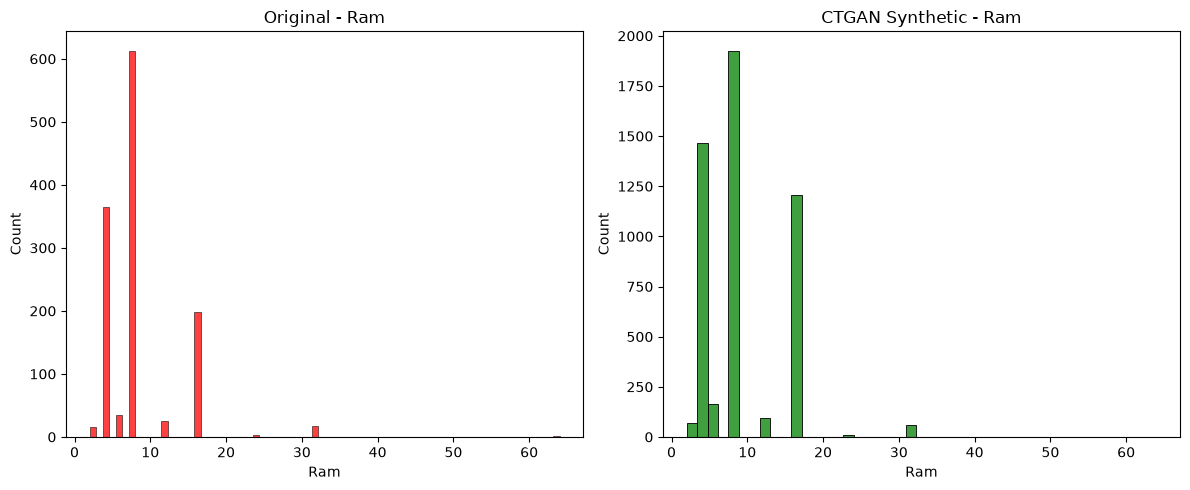

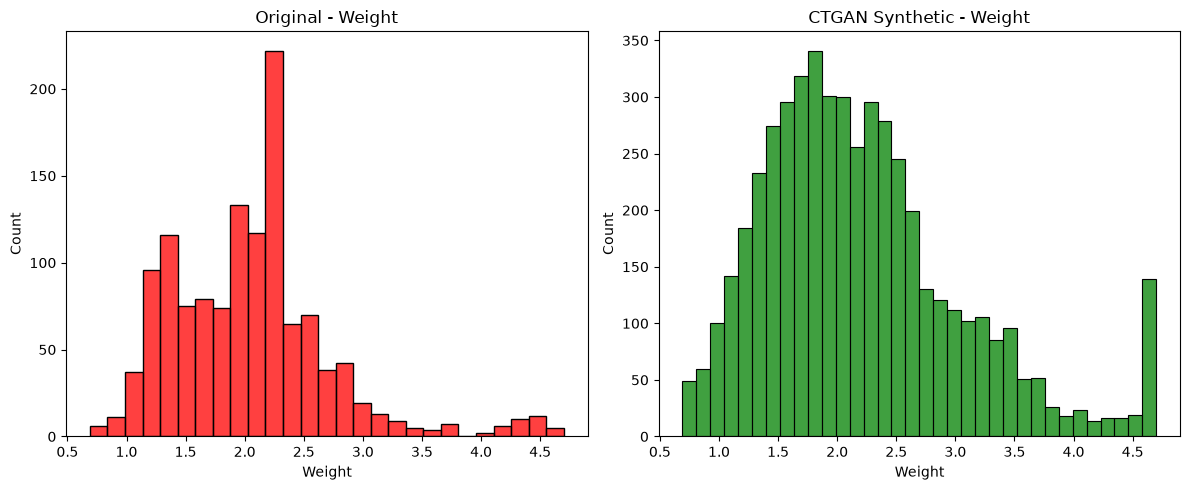

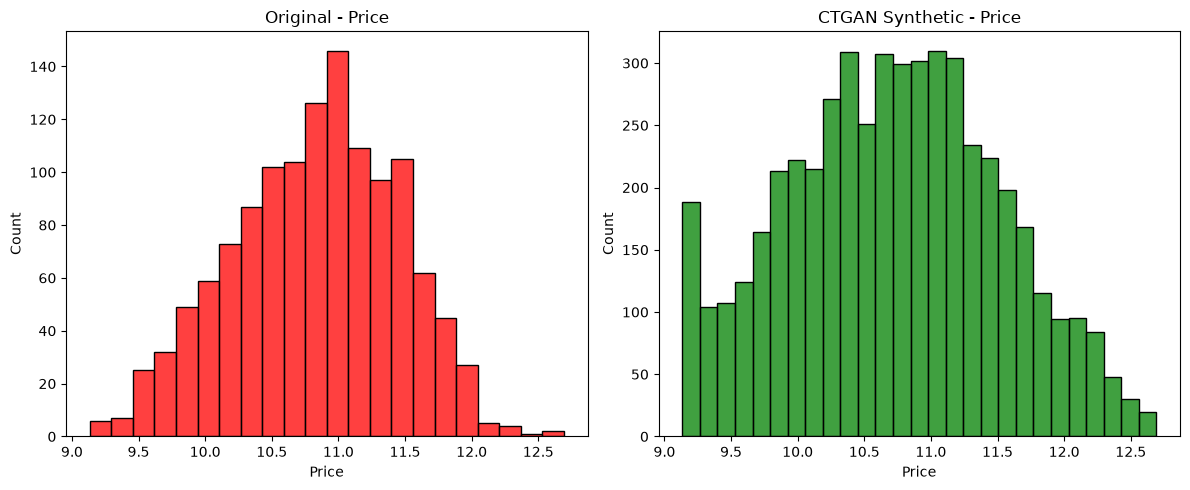

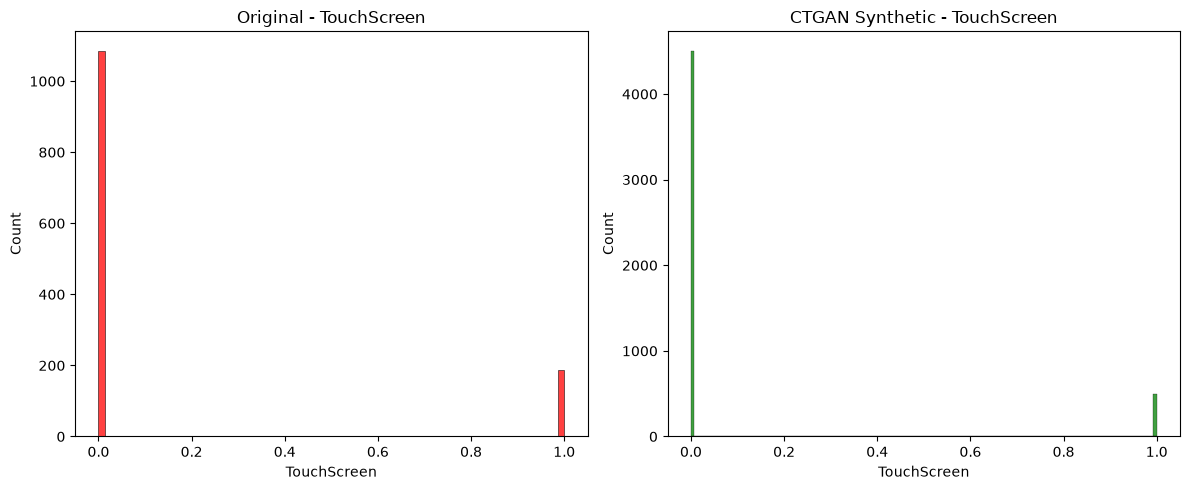

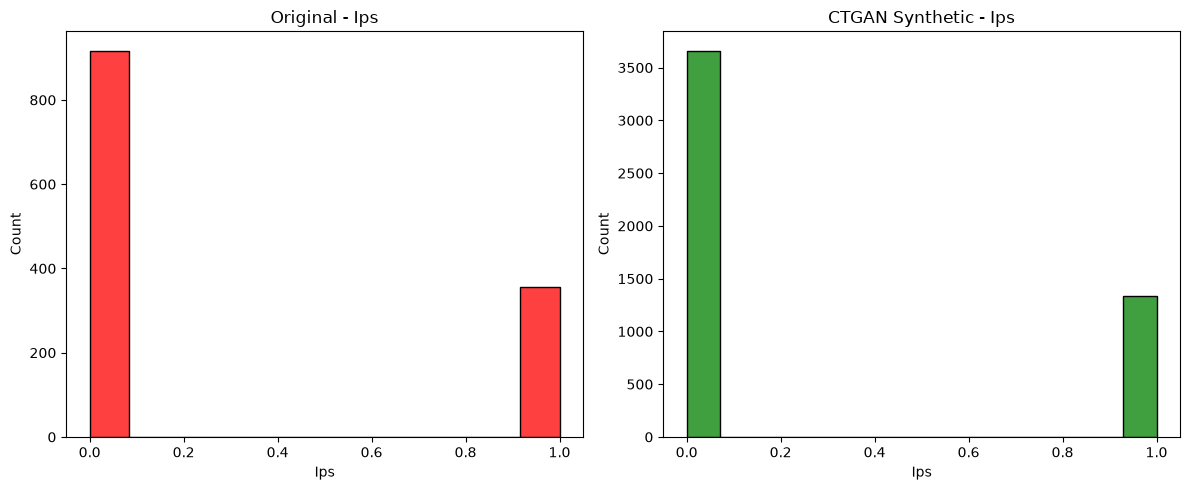

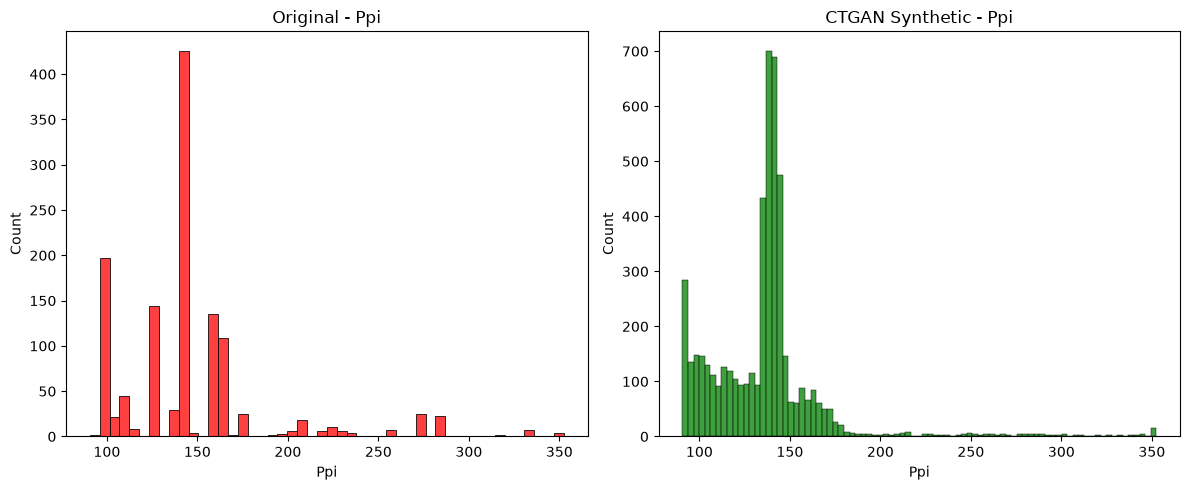

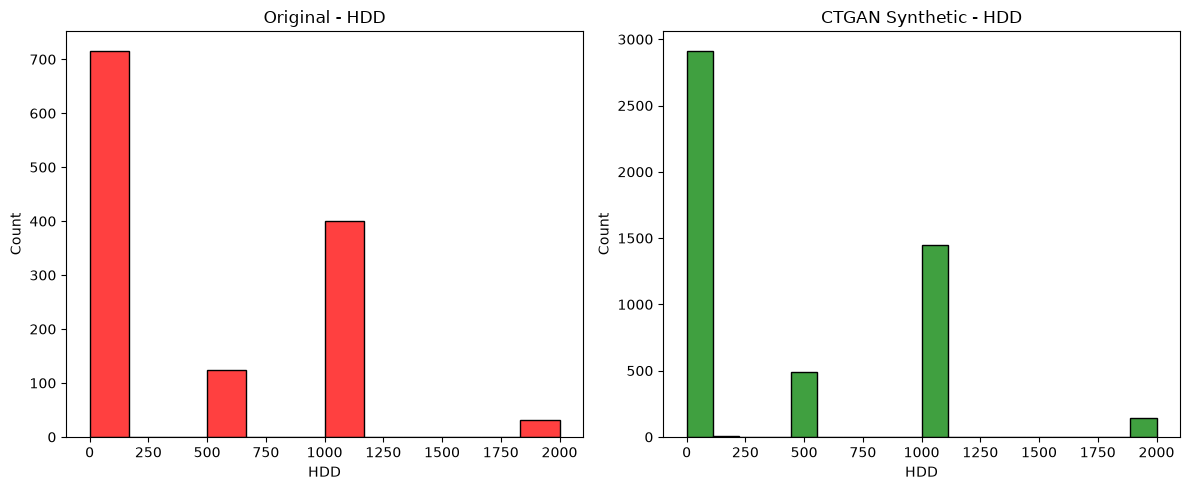

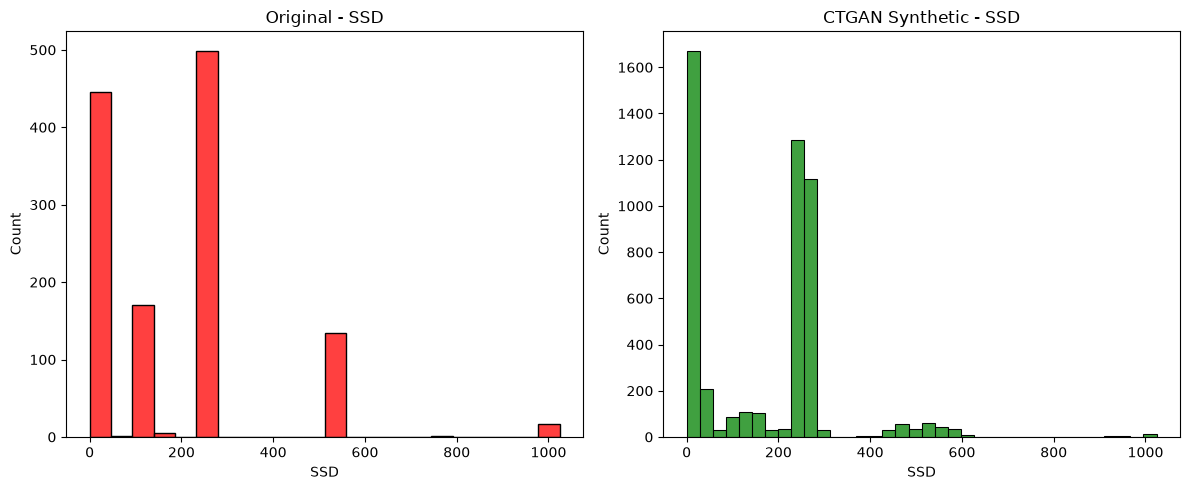

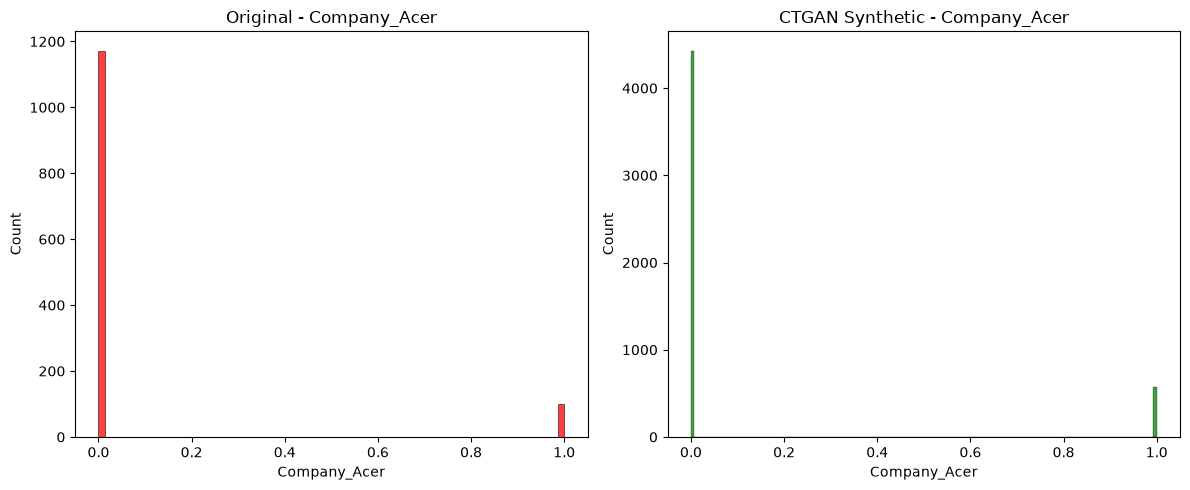

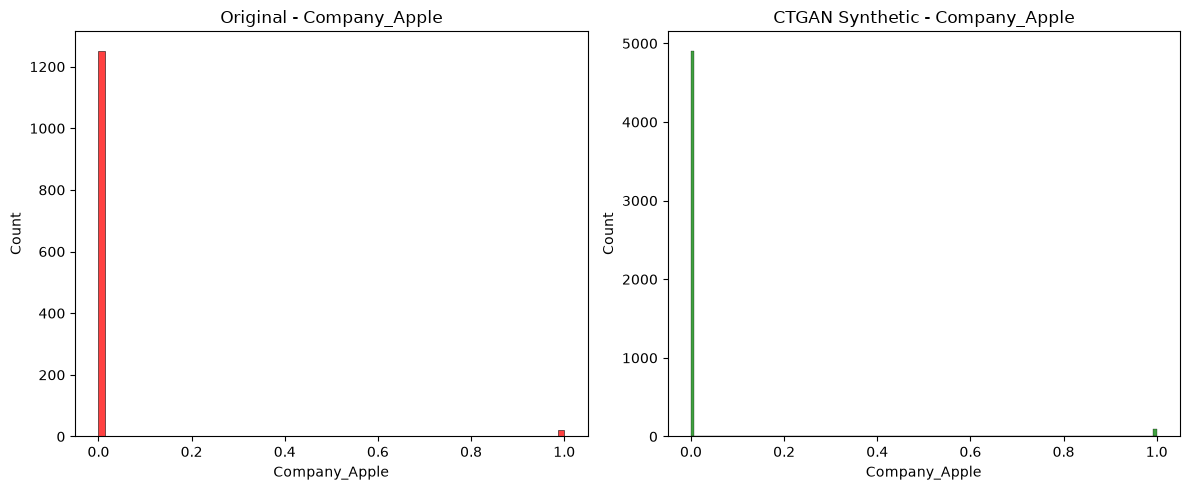

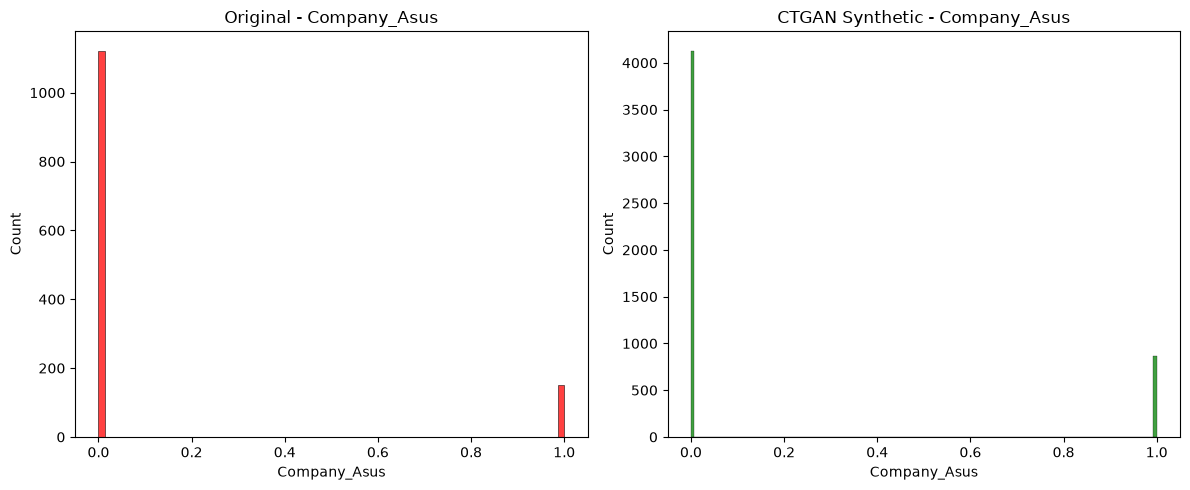

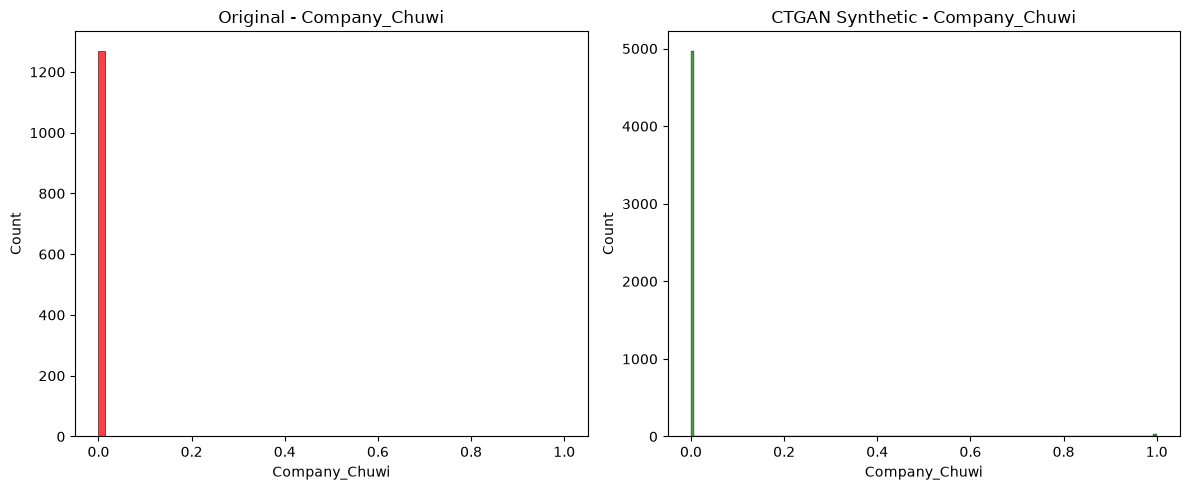

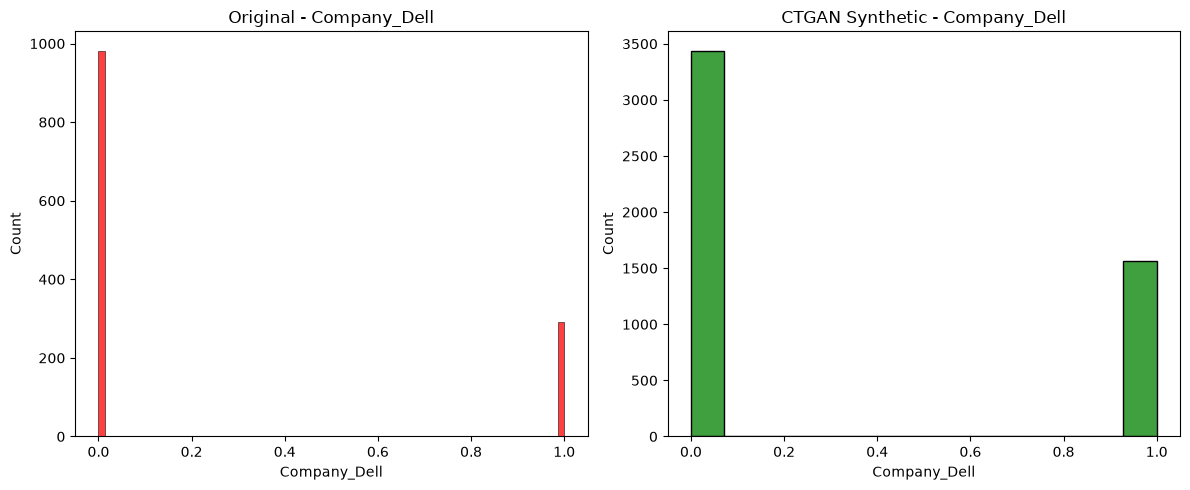

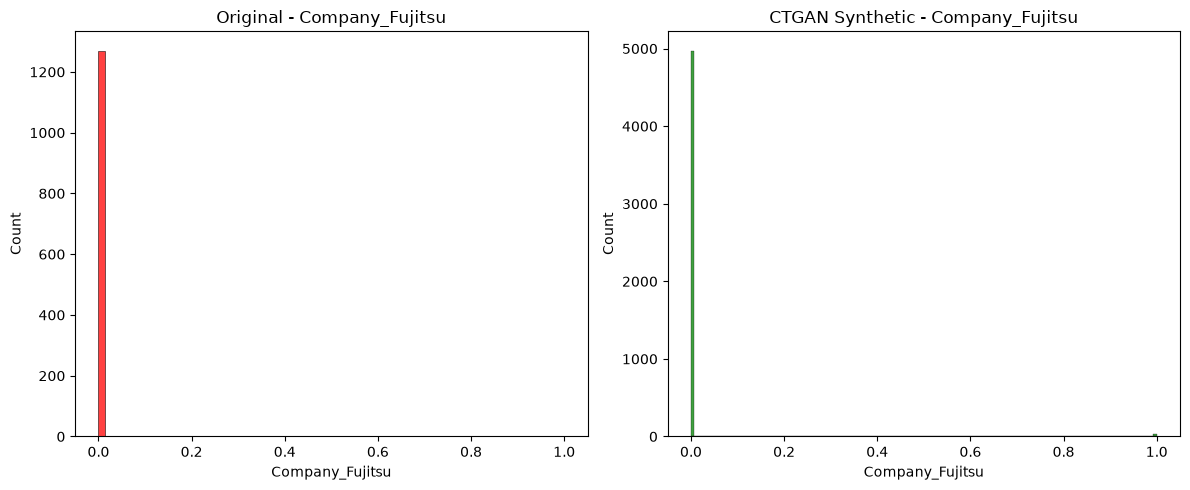

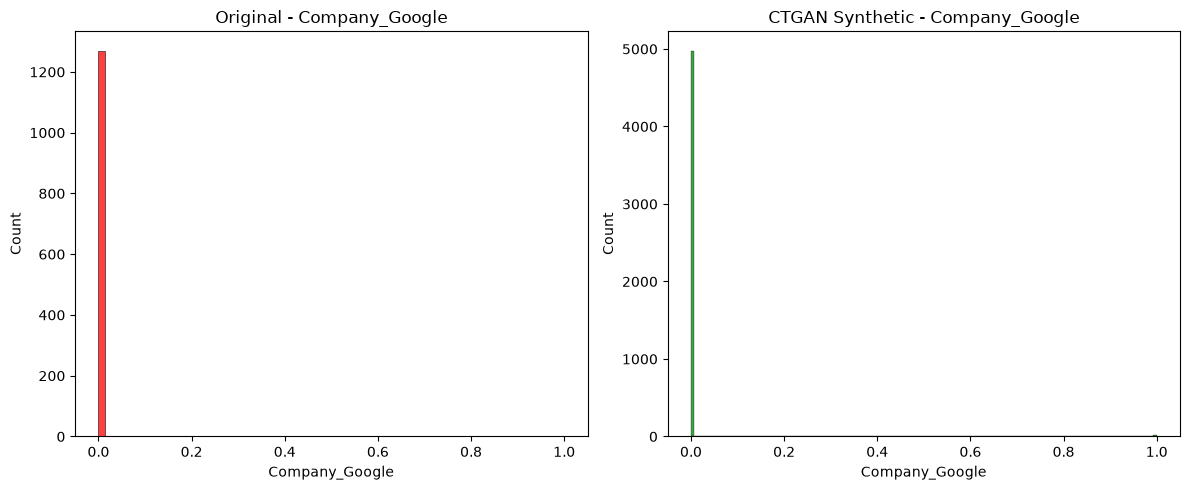

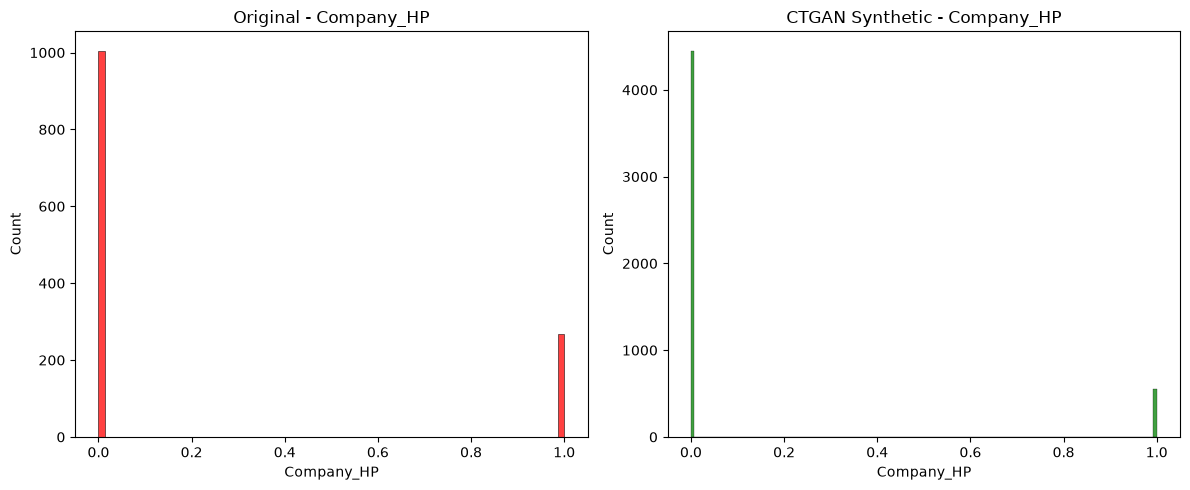

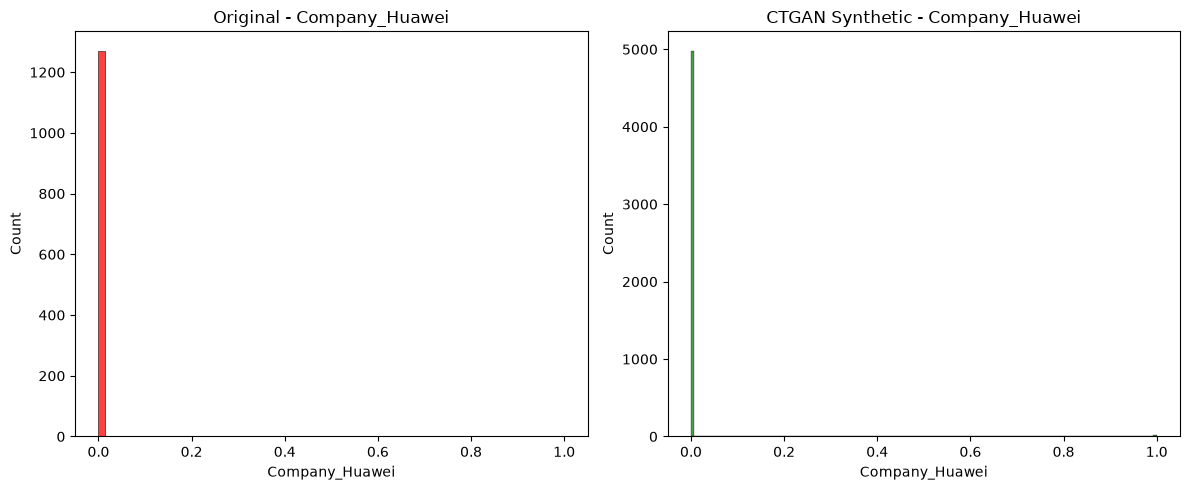

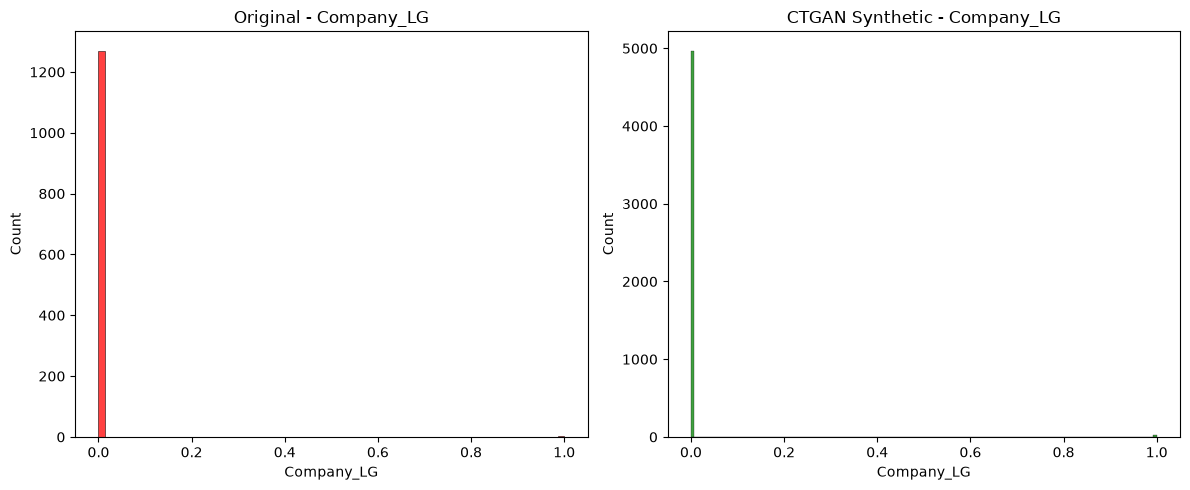

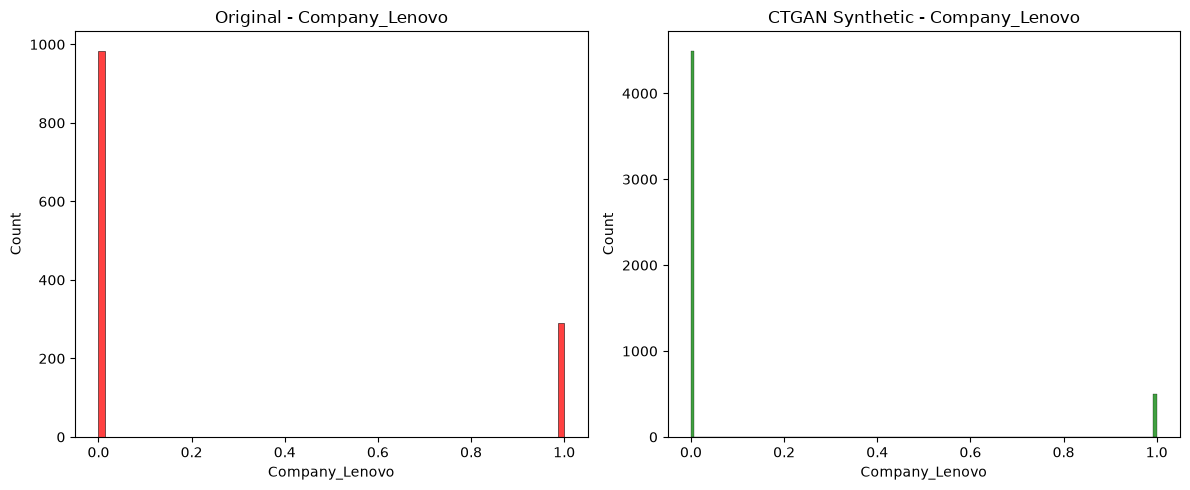

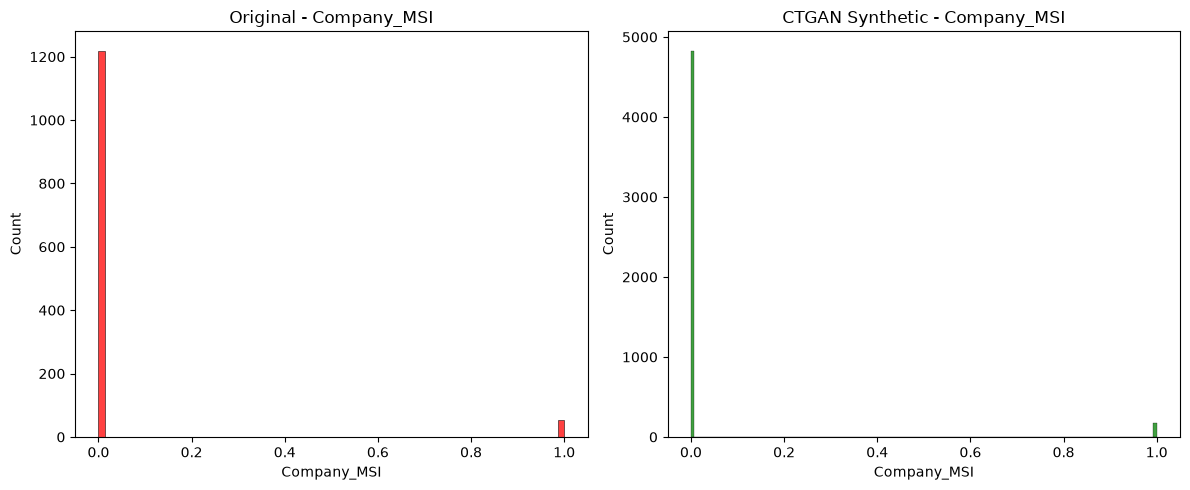

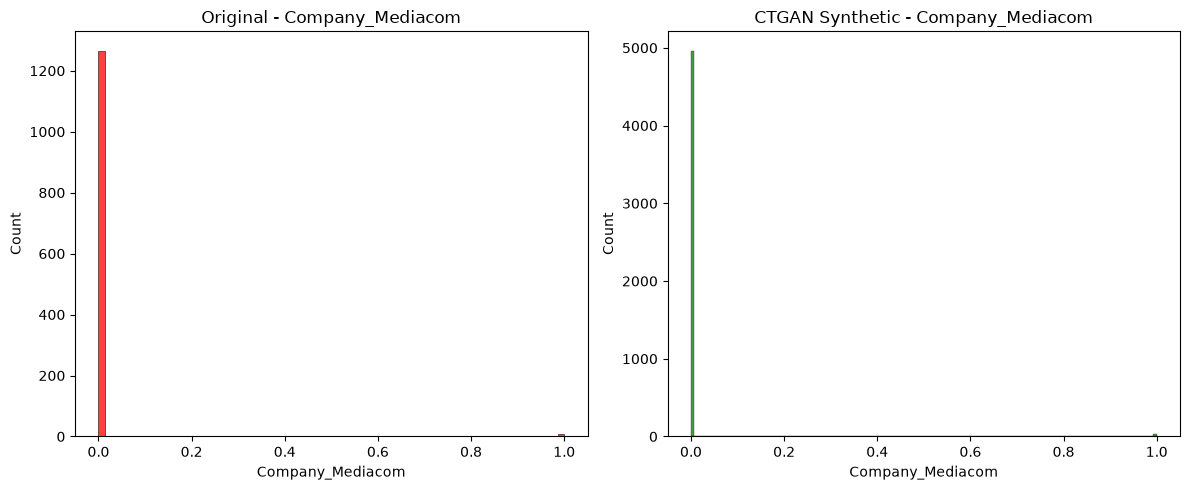

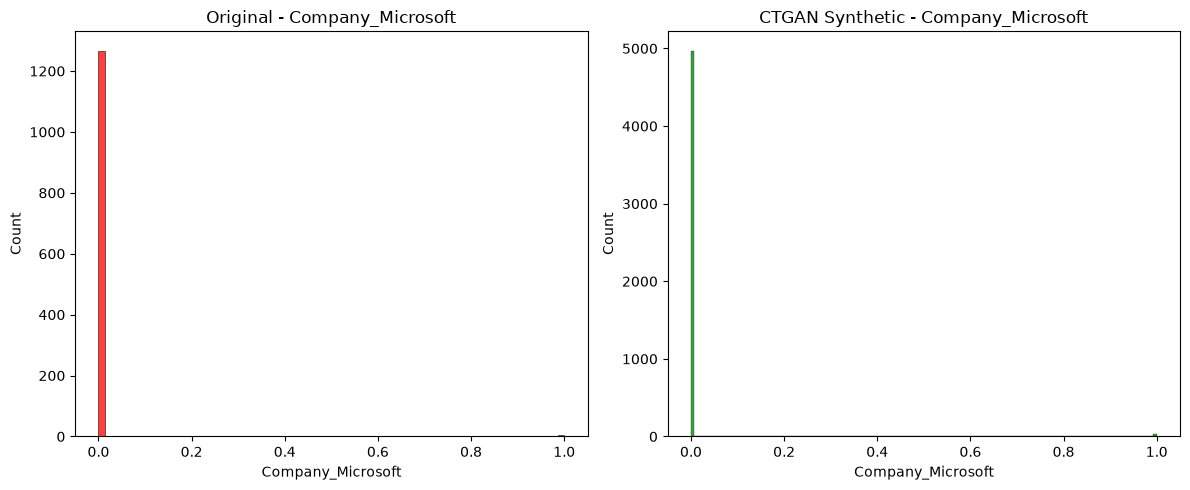

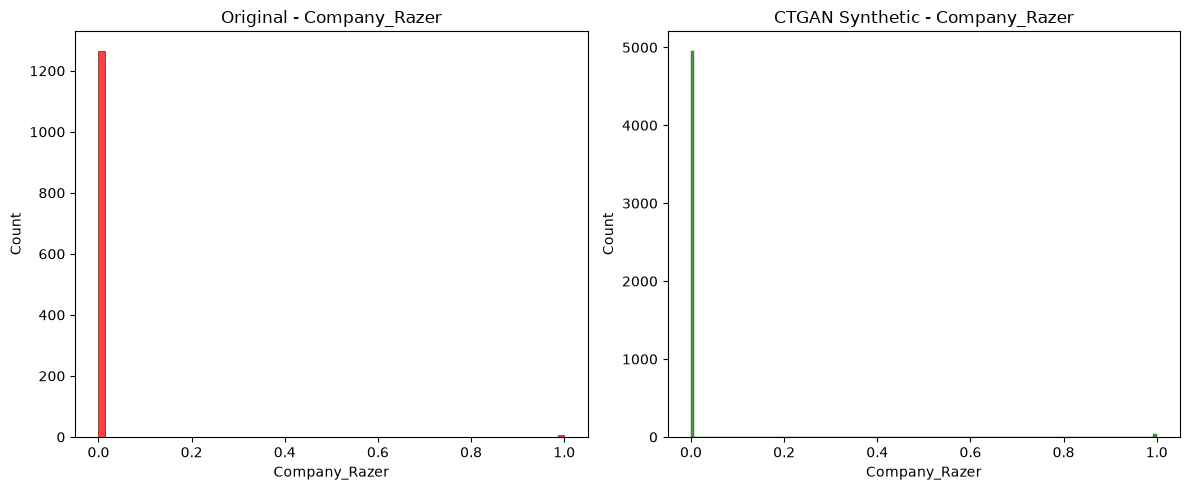

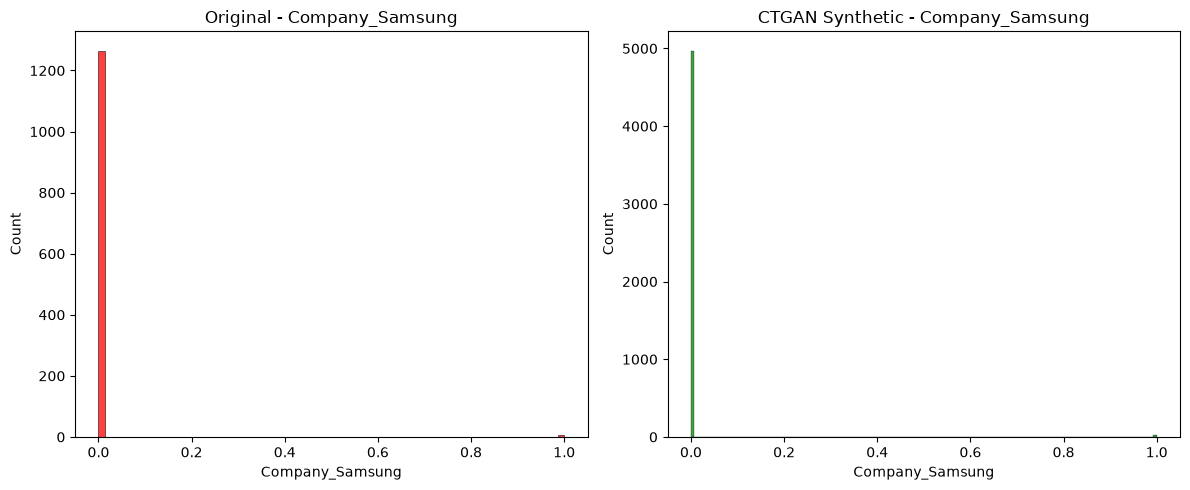

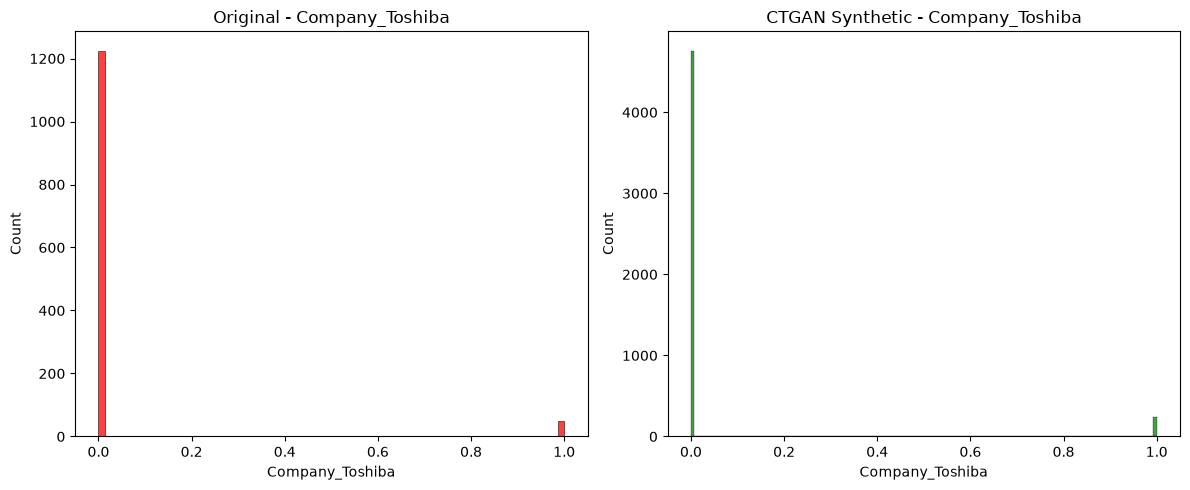

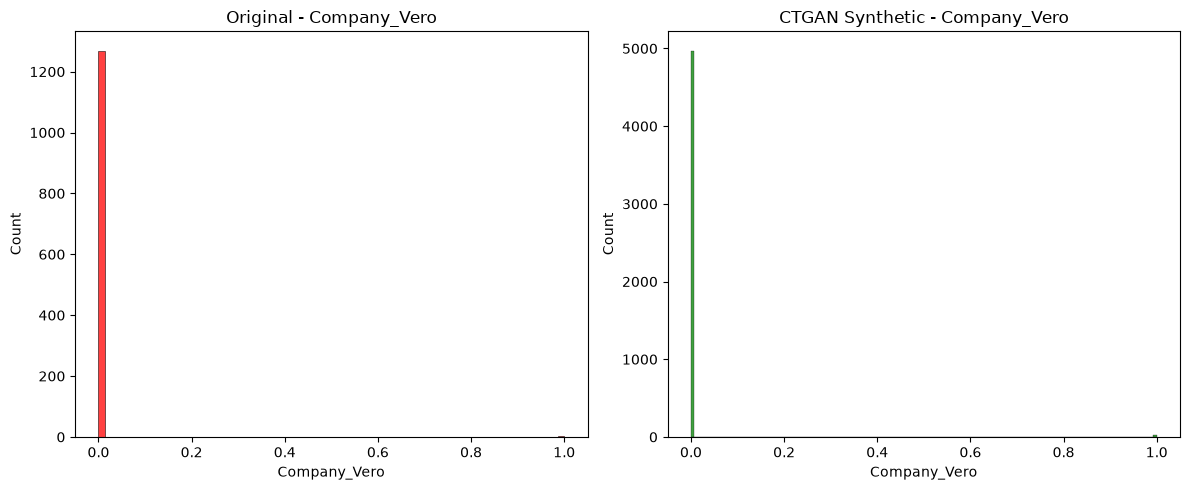

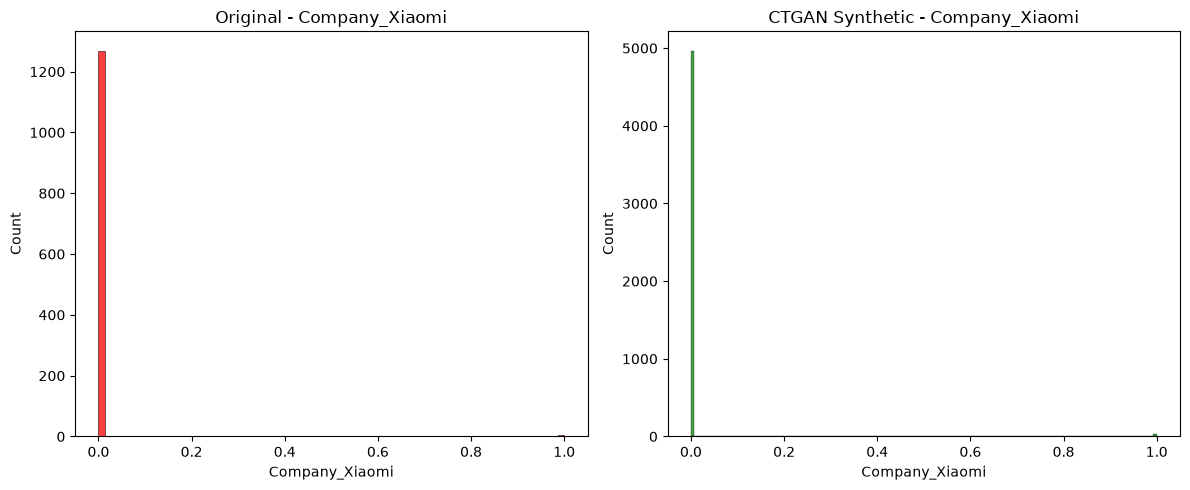

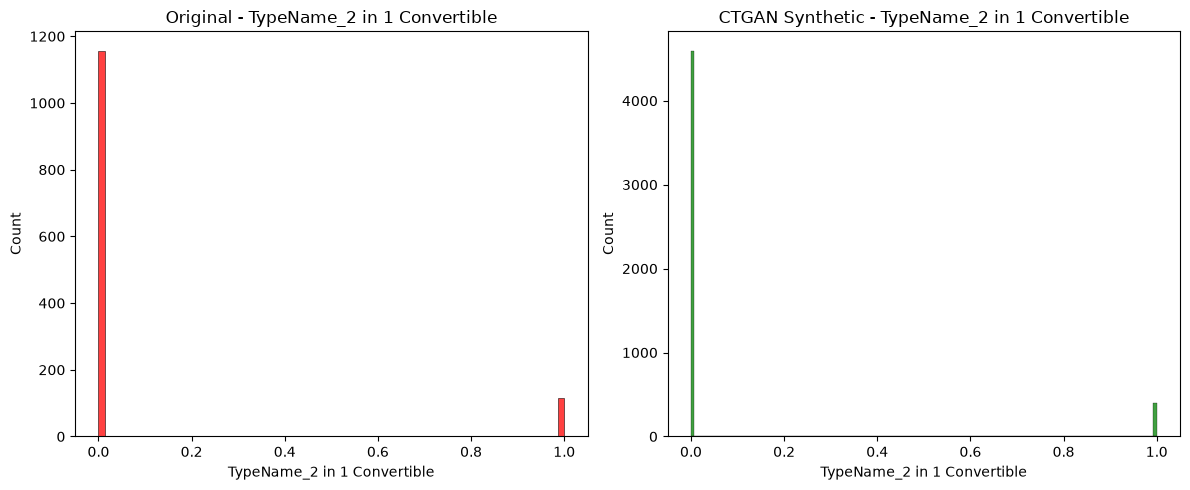

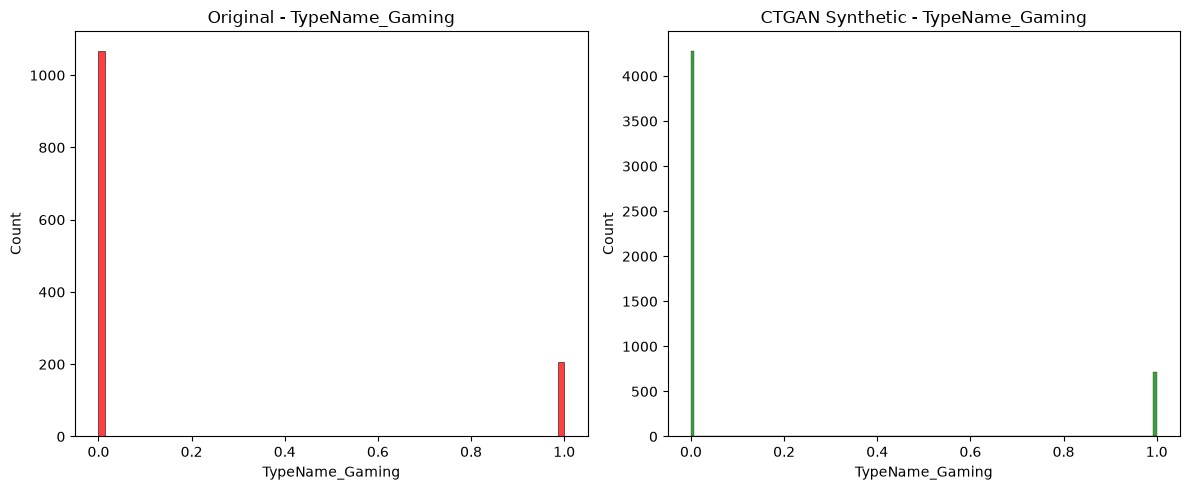

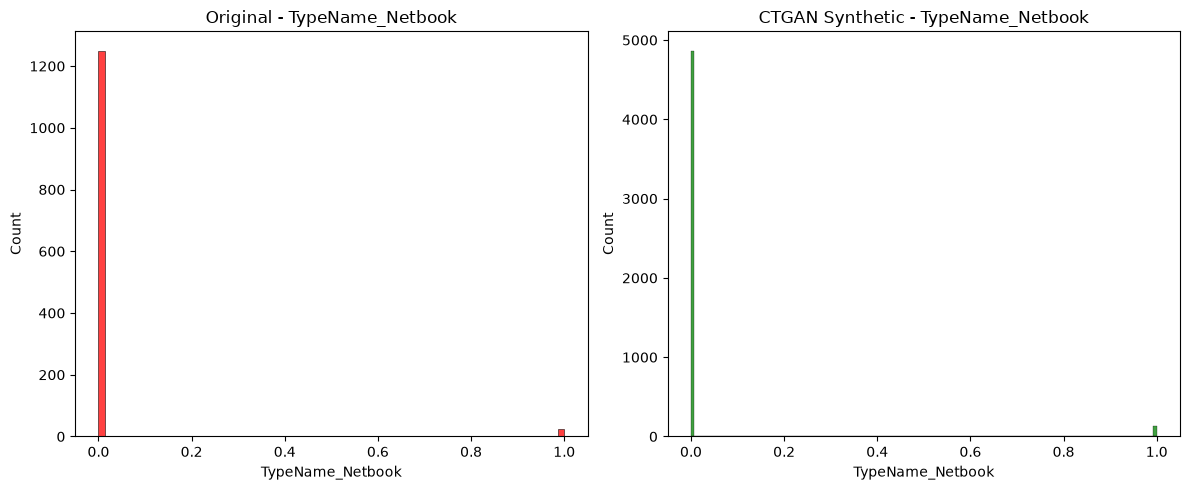

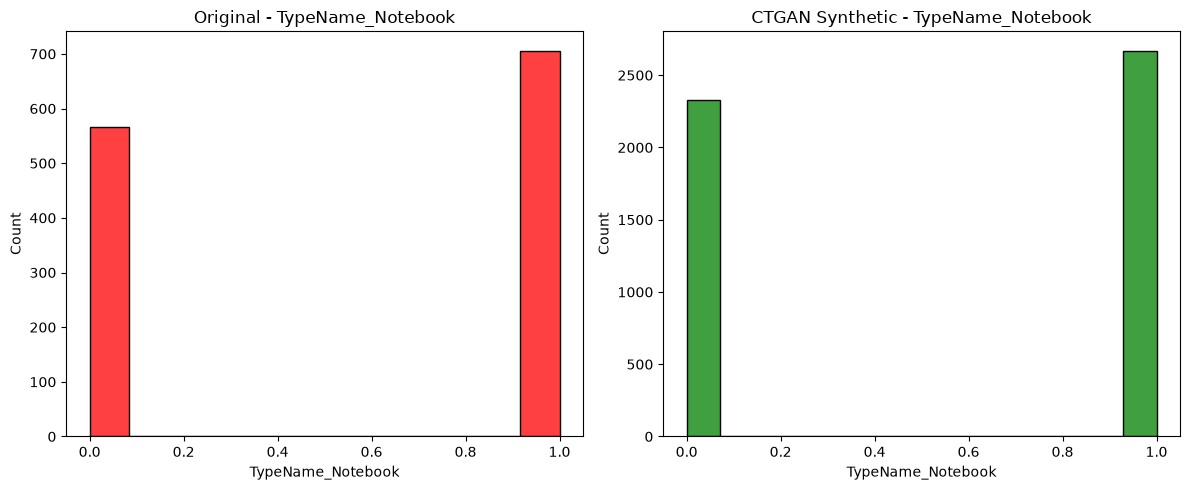

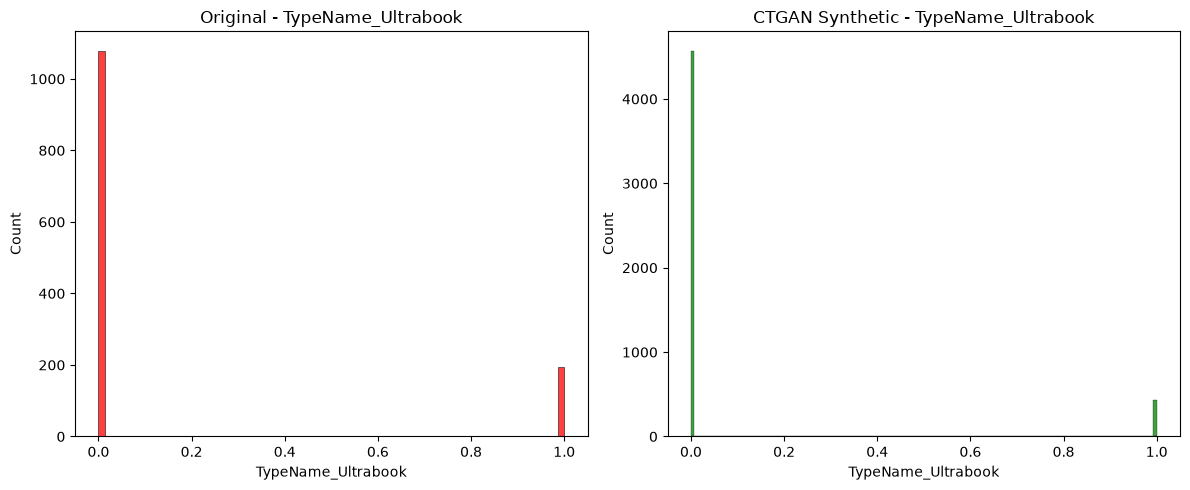

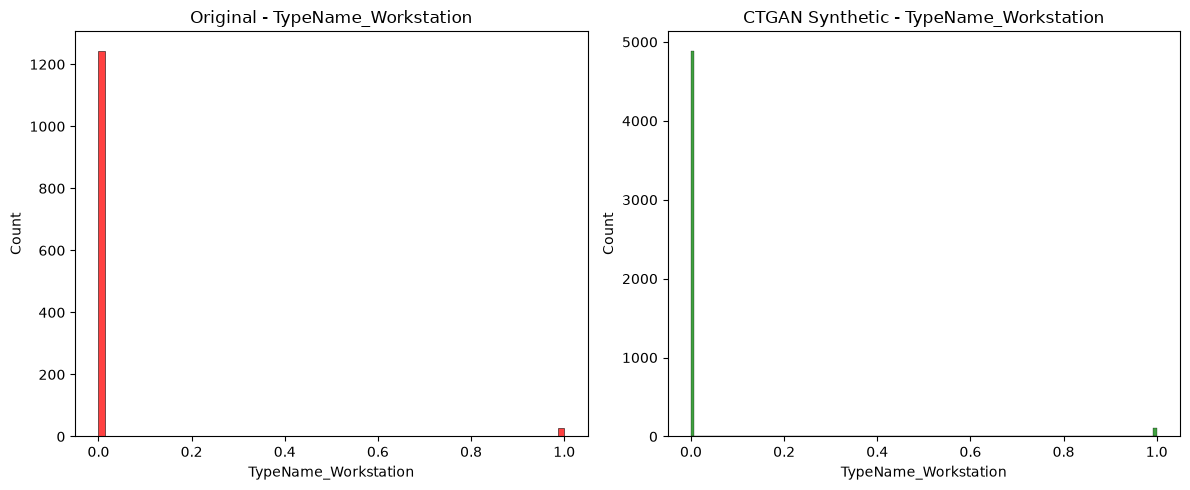

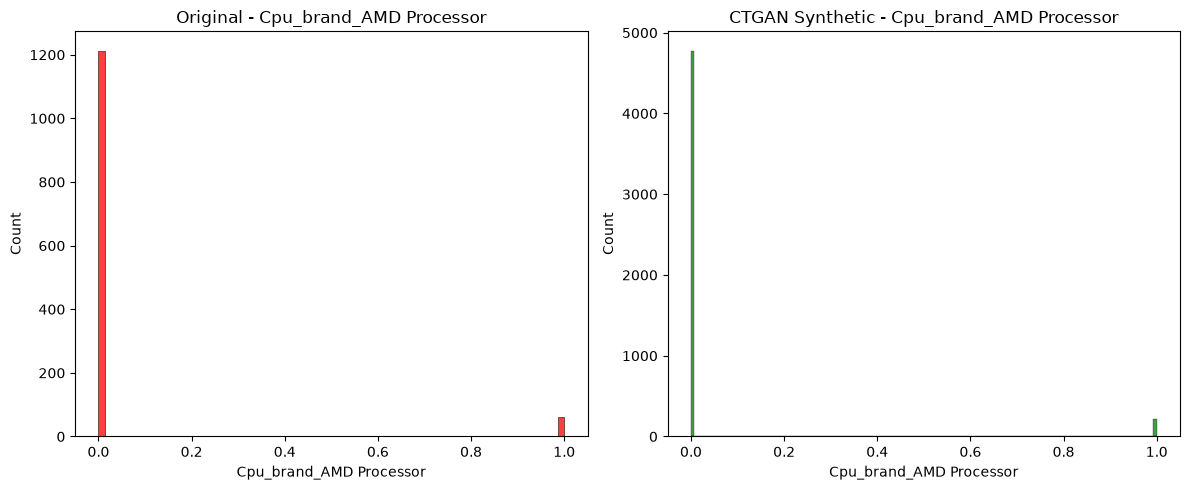

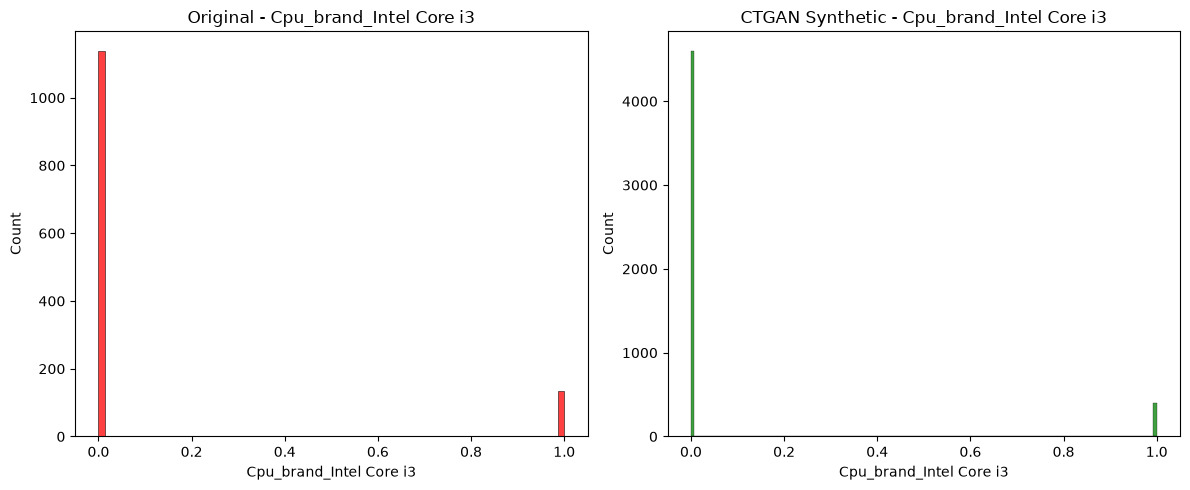

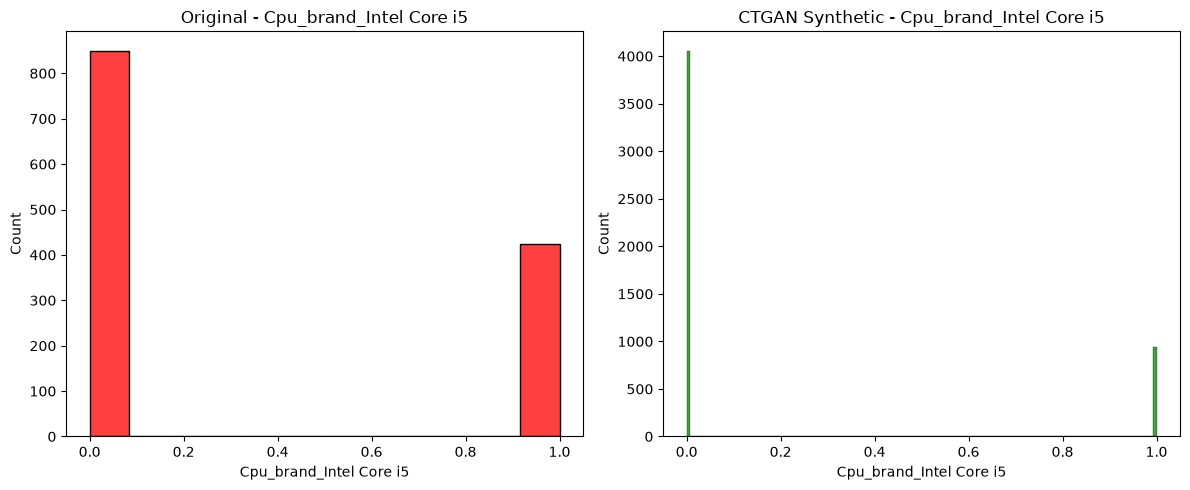

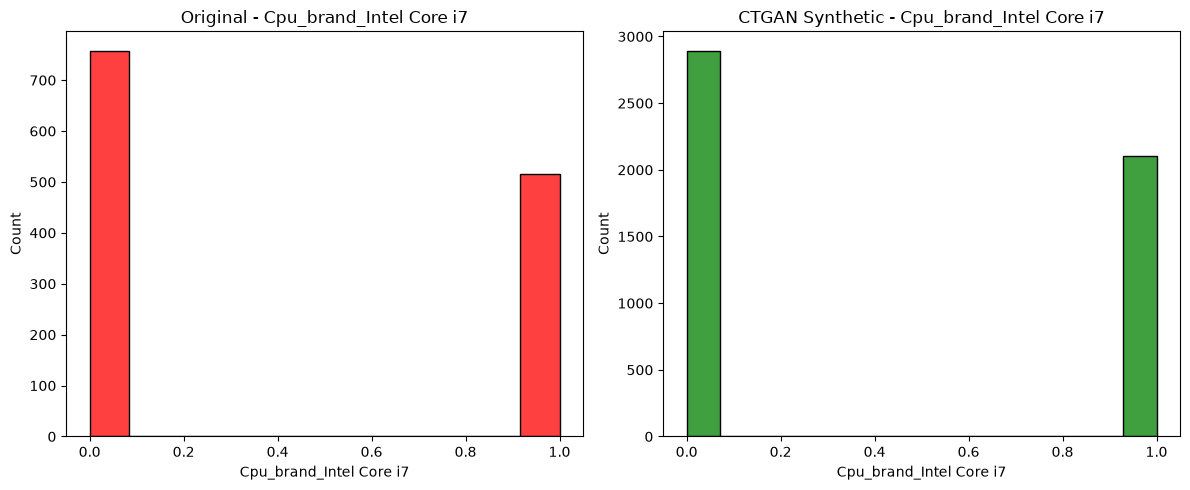

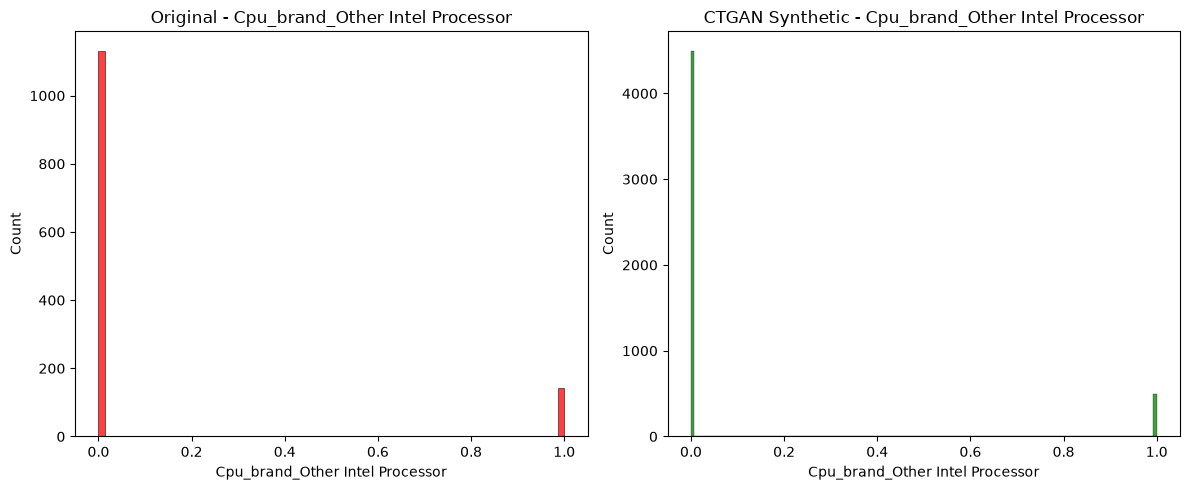

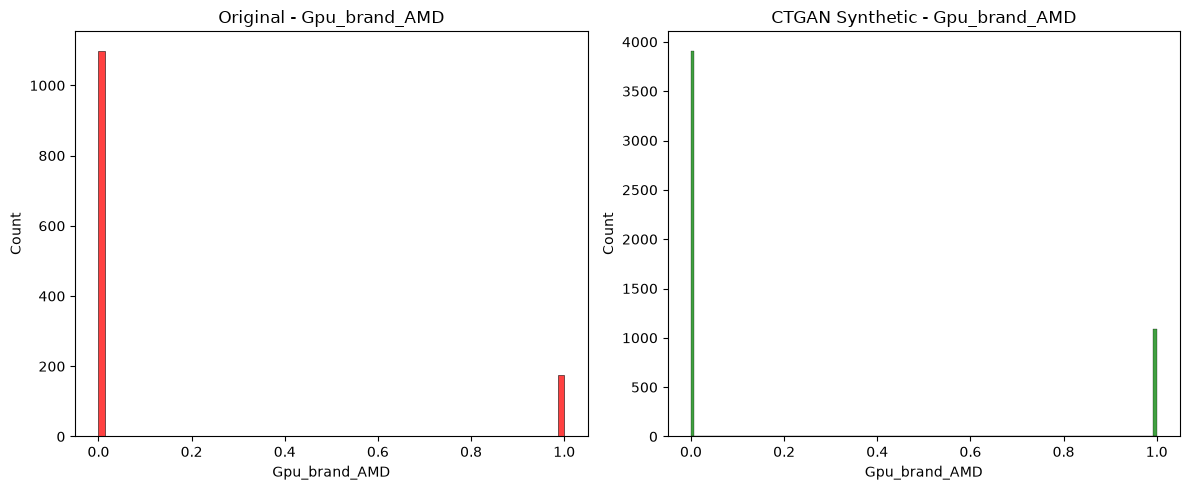

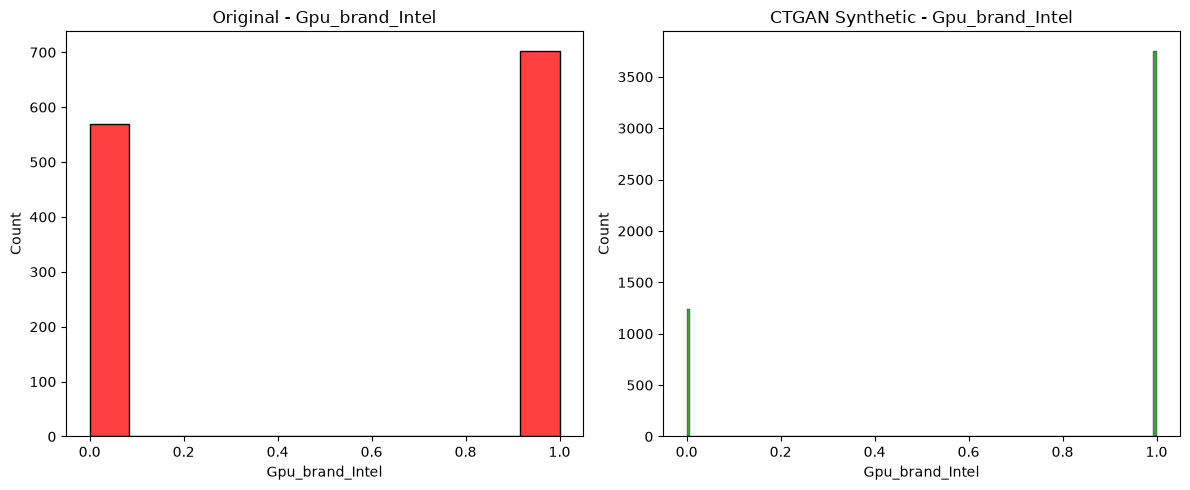

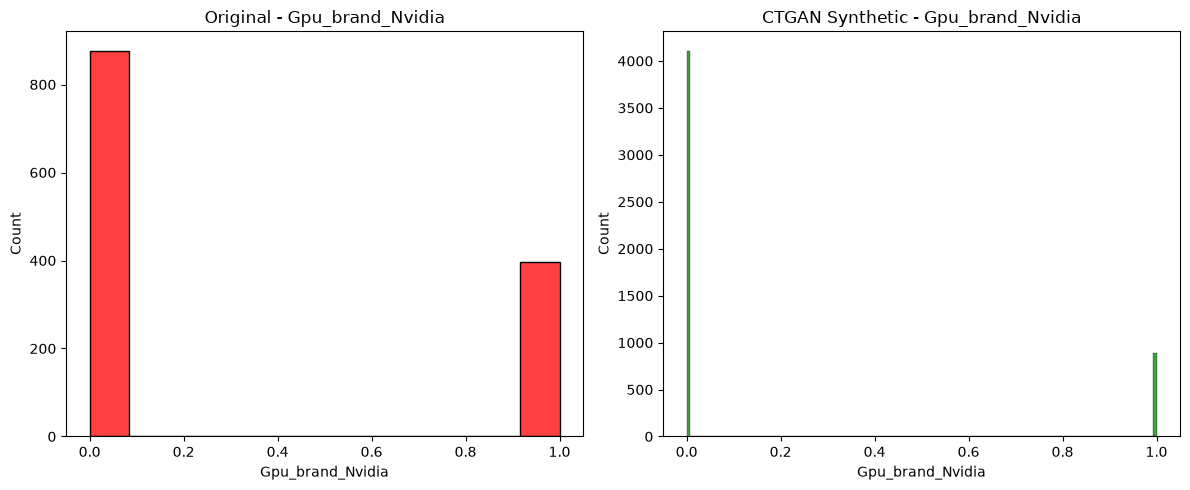

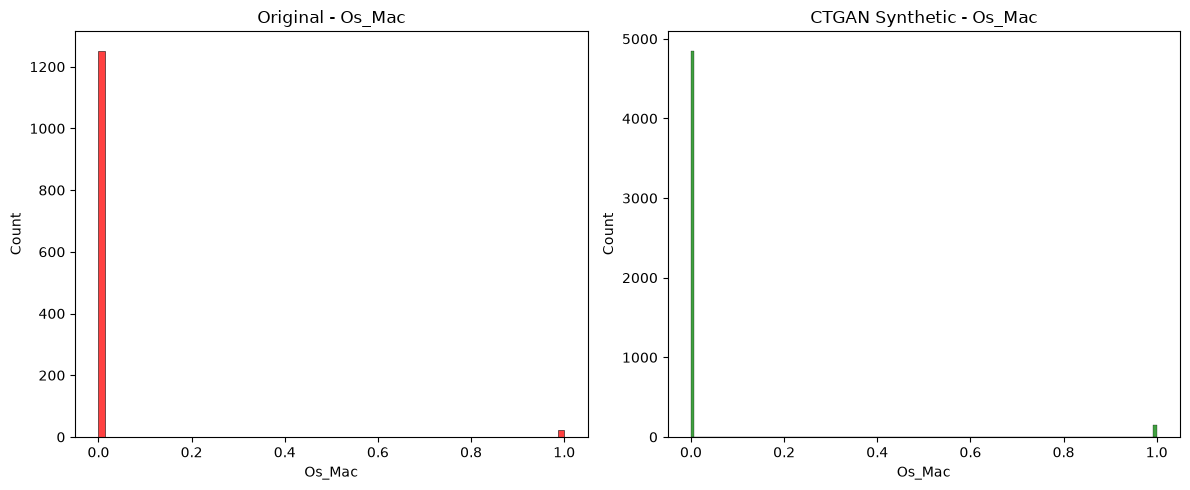

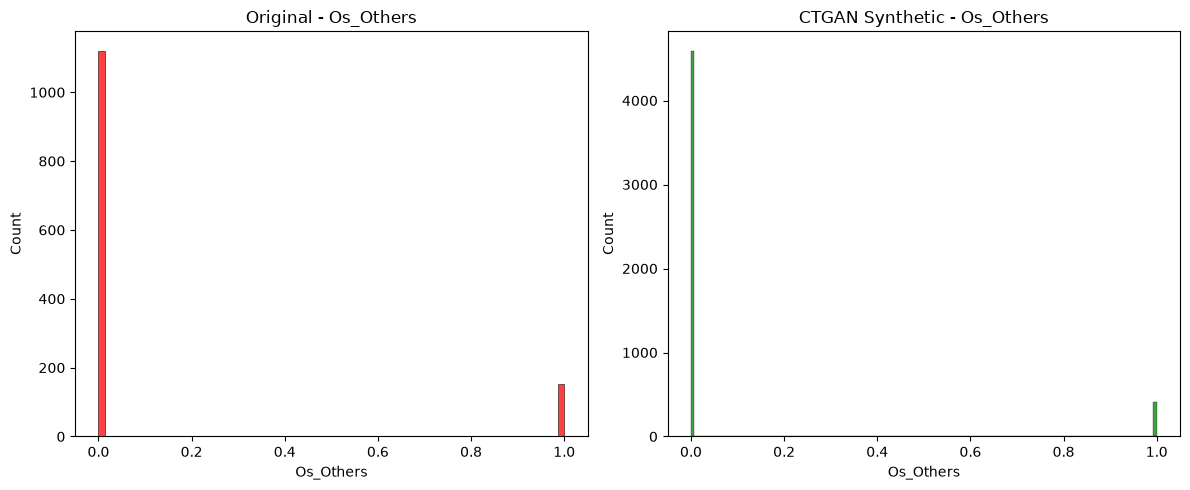

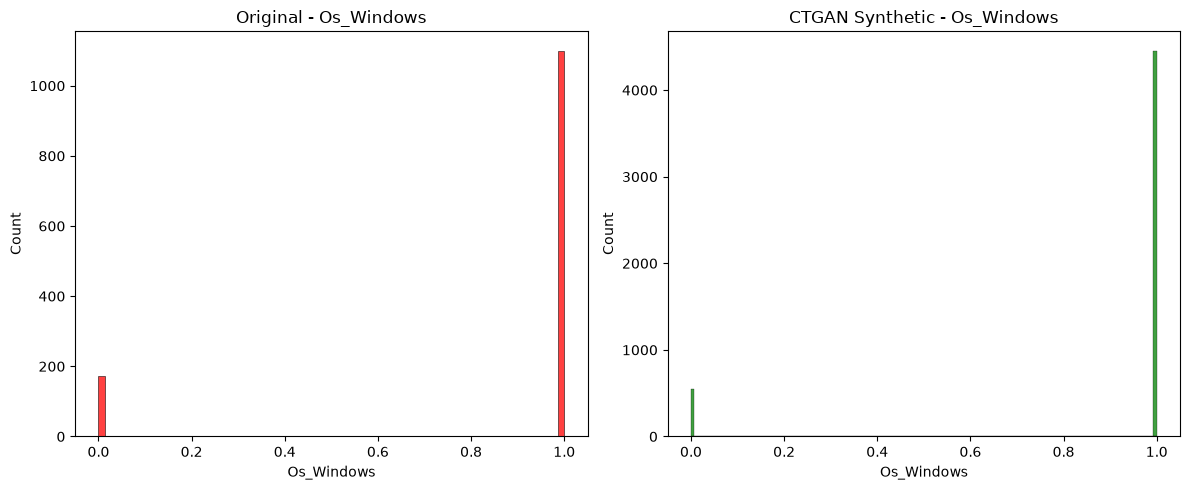

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

# Extract the synthetic DataFrame
synthetic_df = synthetic_data["laptops"]

# Compare original and synthetic datasets
for column in df.columns:

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    sns.histplot(df[column], ax=axes[0], color="red")
    sns.histplot(synthetic_df[column], ax=axes[1], color="green")

    axes[0].set_title("Original - " + column)
    axes[1].set_title("CTGAN Synthetic - " + column)

    plt.tight_layout()
    plt.show()

In [ ]:
# Correlation heatmap of the original data
df.corr(numeric_only=True).style.background_gradient(cmap="coolwarm", vmin=-1, vmax=1)

,Ram,Weight,Price,TouchScreen,Ips,Ppi,HDD,SSD,Company_Acer,Company_Apple,Company_Asus,Company_Chuwi,Company_Dell,Company_Fujitsu,Company_Google,Company_HP,Company_Huawei,Company_LG,Company_Lenovo,Company_MSI,Company_Mediacom,Company_Microsoft,Company_Razer,Company_Samsung,Company_Toshiba,Company_Vero,Company_Xiaomi,TypeName_2 in 1 Convertible,TypeName_Gaming,TypeName_Netbook,TypeName_Notebook,TypeName_Ultrabook,TypeName_Workstation,Cpu_brand_AMD Processor,Cpu_brand_Intel Core i3,Cpu_brand_Intel Core i5,Cpu_brand_Intel Core i7,Cpu_brand_Other Intel Processor,Gpu_brand_AMD,Gpu_brand_Intel,Gpu_brand_Nvidia,Os_Mac,Os_Others,Os_Windows
Ram,1.000000,0.389134,0.680519,0.113316,0.202809,0.294927,0.097340,0.599552,-0.139844,0.022503,0.097426,-0.036056,0.083574,-0.016984,0.021159,-0.150466,-0.003485,0.021159,-0.041724,0.189515,-0.069059,-0.006046,0.160203,0.047624,0.008502,-0.054502,0.017099,0.012885,0.481464,-0.095231,-0.416821,0.083681,0.060962,-0.106812,-0.249099,-0.205946,0.560037,-0.251019,-0.095976,-0.321967,0.417062,0.022503,-0.172092,0.154478
Weight,0.389134,1.000000,0.151386,-0.292288,0.023966,-0.319499,0.510876,-0.056985,0.053175,-0.139510,0.105989,-0.022844,0.084200,0.013966,-0.068373,-0.098261,-0.058769,-0.072005,-0.026904,0.194892,-0.078247,-0.081241,0.017186,-0.083788,-0.118623,-0.059678,-0.035340,-0.232482,0.595088,-0.146656,0.023871,-0.441417,0.097102,0.063244,0.027330,-0.148678,0.231011,-0.207557,0.104665,-0.600306,0.567158,-0.139510,0.002328,0.049653
Price,0.680519,0.151386,1.000000,0.194289,0.279240,0.480687,-0.097361,0.658808,-0.249514,0.093356,-0.018449,-0.089796,0.084610,-0.020767,0.042908,-0.019252,0.026080,0.062273,-0.042994,0.188654,-0.142000,0.052978,0.133549,0.044365,0.069182,-0.133899,0.015207,0.093719,0.362537,-0.146852,-0.566663,0.306406,0.206745,-0.230121,-0.324742,0.005343,0.593245,-0.462839,-0.202803,-0.192402,0.357157,0.093356,-0.348033,0.294626
TouchScreen,0.113316,-0.292288,0.194289,1.000000,0.136973,0.452107,-0.205105,0.252142,-0.039711,-0.053742,-0.056149,-0.020168,0.112308,-0.020168,0.117126,-0.067322,-0.016461,0.071361,0.034679,-0.087338,-0.000849,0.165837,0.089173,0.023161,-0.023894,-0.023297,-0.023297,0.747635,-0.151616,-0.022968,-0.378208,0.101887,-0.033612,-0.092289,-0.084485,-0.019492,0.096519,0.023245,-0.145734,0.257626,-0.168590,-0.053742,-0.077524,0.093333
Ips,0.202809,0.023966,0.279240,0.136973,1.000000,0.288833,-0.090411,0.215197,0.043744,0.139155,-0.077014,0.005813,-0.151626,-0.030283,-0.030283,-0.077049,0.063665,0.078004,0.218010,-0.070352,0.072007,-0.042877,-0.022664,-0.049550,0.042051,-0.003709,0.090107,0.167611,0.146043,-0.031957,-0.297339,0.125382,0.033901,-0.089023,-0.128168,-0.027101,0.178221,-0.052596,-0.125642,-0.047857,0.144637,0.139155,-0.110689,0.053016
Ppi,0.294927,-0.319499,0.480687,0.452107,0.288833,1.000000,-0.290774,0.499899,-0.138961,0.167061,-0.080085,0.041119,0.074924,-0.052665,0.099172,-0.037351,0.048757,-0.000407,0.026287,-0.036807,0.031264,0.086428,0.162811,0.008844,-0.028050,0.001461,0.008467,0.236097,-0.028407,-0.017538,-0.392139,0.373808,0.036066,-0.139659,-0.202736,-0.032020,0.247884,-0.047048,-0.158354,0.121344,-0.012838,0.167061,-0.146119,0.076168
HDD,0.097340,0.510876,-0.097361,-0.205105,-0.090411,-0.290774,1.000000,-0.400625,0.015237,-0.103468,0.134444,-0.038829,0.065416,-0.007544,-0.038829,-0.062793,-0.031691,-0.038829,-0.074465,0.230759,-0.058749,-0.054977,-0.059406,-0.044337,-0.122307,-0.044853,-0.044853,-0.171263,0.376333,-0.108369,0.100954,-0.319763,-0.066062,0.076426,0.094222,-0.117139,0.083253,-0.098129,0.165657,-0.413907,0.321677,-0.103468,0.084745,-0.041731
SSD,0.599552,-0.056985,0.658808,0.252142,0.215197,0.499899,-0.400625,1.000000,-0.152569,0.001875,-0.005683,-0.048549,0.024965,-0.004063,0.029302,-0.049146,0.042070,0.084910,0.052386,0.051973,-0.066985,0.025741,0.156341,0.009275,0.042904,-0.056082,0.021001,0.155333,0.115560,-0.048957,-0.387439,0.284835,0.063889,-0.098747,-0.227689,-0.100613,0.443746,-0.253631,-0.132946,-0.025449,0.125987,0.00187

In [ ]:
# Correlation heatmap of the synthetic data
# Extract synthetic DataFrame
synthetic_df = synthetic_data["laptops"]

# Generate correlation matrix for numerical columns
synthetic_df.corr(numeric_only=True).style.background_gradient(
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

,Ram,Weight,Price,TouchScreen,Ips,Ppi,HDD,SSD,Company_Acer,Company_Apple,Company_Asus,Company_Chuwi,Company_Dell,Company_Fujitsu,Company_Google,Company_HP,Company_Huawei,Company_LG,Company_Lenovo,Company_MSI,Company_Mediacom,Company_Microsoft,Company_Razer,Company_Samsung,Company_Toshiba,Company_Vero,Company_Xiaomi,TypeName_2 in 1 Convertible,TypeName_Gaming,TypeName_Netbook,TypeName_Notebook,TypeName_Ultrabook,TypeName_Workstation,Cpu_brand_AMD Processor,Cpu_brand_Intel Core i3,Cpu_brand_Intel Core i5,Cpu_brand_Intel Core i7,Cpu_brand_Other Intel Processor,Gpu_brand_AMD,Gpu_brand_Intel,Gpu_brand_Nvidia,Os_Mac,Os_Others,Os_Windows
Ram,1.000000,-0.003921,0.019201,0.015158,0.008041,0.004373,0.006994,-0.003326,0.012678,-0.026453,0.019238,0.013693,0.010475,0.028428,-0.000575,-0.008428,-0.012345,0.023537,-0.031281,0.017314,0.009862,-0.019263,-0.003304,0.036530,0.000211,-0.027378,-0.003785,0.003243,-0.003824,-0.015264,-0.029277,-0.000089,0.010860,0.030168,-0.005282,0.009752,0.022973,0.019085,0.001089,0.033611,-0.001315,0.005386,-0.004944,-0.010992
Weight,-0.003921,1.000000,-0.015847,0.009254,0.004033,-0.003470,0.000127,-0.015226,0.032711,0.003807,0.025470,0.015930,0.021673,0.011043,-0.011927,-0.004742,-0.011979,-0.005700,-0.044185,-0.005367,-0.001952,0.017067,0.009690,-0.002008,-0.016986,-0.006044,0.007885,-0.005547,0.023993,0.032309,-0.023510,-0.009629,-0.030639,0.028999,0.057577,-0.001813,-0.006637,-0.007262,0.001205,0.016601,0.015305,-0.004410,0.017177,-0.020177
Price,0.019201,-0.015847,1.000000,0.023999,-0.023064,-0.015126,-0.011659,-0.002704,0.035477,0.006224,-0.026397,-0.004014,-0.023910,-0.009275,-0.017143,-0.012445,-0.019849,0.004264,-0.008750,-0.004351,-0.022546,0.018571,0.008081,-0.029217,0.012127,-0.005493,-0.039216,-0.031745,0.000545,-0.004173,0.020454,-0.002678,0.000180,-0.005204,0.034958,-0.013247,0.051949,-0.018169,-0.003796,0.010328,-0.016989,0.013373,-0.025854,-0.010174
TouchScreen,0.015158,0.009254,0.023999,1.000000,0.002992,-0.016453,-0.009968,0.000719,-0.006759,0.004636,0.023390,0.022725,0.021839,0.022725,0.020014,-0.015103,0.003732,-0.025696,-0.008020,0.015280,-0.020231,0.020130,0.021014,0.011140,-0.001778,-0.006840,0.007107,0.010509,-0.001520,-0.004644,0.002337,-0.007447,-0.013016,0.003618,-0.000113,0.013929,0.029006,0.012515,0.017269,0.004277,0.003939,0.005570,0.007291,-0.007242
Ips,0.008041,0.004033,-0.023064,0.002992,1.000000,0.003404,0.001275,0.018598,0.013293,0.004579,-0.019045,0.006513,0.043826,0.006513,0.002627,0.024934,-0.004288,-0.011896,0.019965,0.005483,0.012603,0.015141,-0.006174,0.021193,0.004225,-0.003017,0.025093,0.015060,0.002215,0.006688,-0.006361,-0.019960,0.001669,0.023130,0.001591,-0.001464,-0.010050,0.041865,0.012437,-0.011060,0.036200,-0.012350,0.012027,0.014045
Ppi,0.004373,-0.003470,-0.015126,-0.016453,0.003404,1.000000,0.032191,-0.037523,0.026274,-0.034413,0.022751,0.002509,0.010370,0.001743,0.017982,0.007886,-0.033498,0.016691,0.000825,0.007027,0.007563,0.047938,0.013432,-0.002387,0.012375,0.007646,-0.002269,0.006089,-0.025532,0.002309,-0.019322,0.002516,0.014171,0.026786,0.011846,0.015077,0.017315,0.011311,0.021141,0.012116,0.016348,0.015295,0.020231,0.008167
HDD,0.006994,0.000127,-0.011659,-0.009968,0.001275,0.032191,1.000000,-0.002073,0.004254,-0.005540,0.000129,0.003733,0.015445,0.014385,0.004795,-0.009825,0.005040,-0.006864,-0.015561,0.023740,0.035068,0.014931,0.016214,-0.000470,-0.004571,-0.003036,0.020926,-0.001331,0.025124,0.027244,-0.012059,0.007340,0.005031,0.013369,-0.022415,0.008131,0.018397,0.039808,0.021025,0.019162,0.005618,0.021188,0.012345,0.010132
SSD,-0.003326,-0.015226,-0.002704,0.000719,0.018598,-0.037523,-0.002073,1.000000,0.020382,0.015208,-0.009451,-0.029110,-0.001391,-0.008878,-0.004347,0.005122,-0.003316,-0.017098,0.002501,-0.007882,0.009220,0.025117,-0.001827,0.013681,-0.018240,-0.008674,0.014536,-0.006680,0.017271,-0.021321,0.013229,0.014016,0.014013,0.006206,-0.001995,-0.003726,0.019246,-0.000507,-0.004878,-0.021903,0.002826,-0.001510,0.007050,-0.001193
Com

In [ ]:
df.corr(numeric_only=True)['Price']

# Real data: Price is strongly related to Ram (0.68), SSD (0.66),
# Cpu_brand_Intel Core i7 (0.59) and TypeName_Notebook (-0.57)

Ram                                0.68
Weight                             0.15
Price                              1.00
TouchScreen                        0.19
Ips                                0.28
Ppi                                0.48
HDD                               -0.10
SSD                                0.66
Company_Acer                      -0.25
Company_Apple                      0.09
Company_Asus                      -0.02
Company_Chuwi                     -0.09
Company_Dell                       0.08
Company_Fujitsu                   -0.02
Company_Google                     0.04
Company_HP                        -0.02
Company_Huawei                     0.03
Company_LG                         0.06
Company_Lenovo                    -0.04
Company_MSI                        0.19
Company_Mediacom                  -0.14
Company_Microsoft                  0.05
Company_Razer                      0.13
Company_Samsung                    0.04
Company_Toshiba                    0.07


In [ ]:
# Extract the synthetic laptop DataFrame
synthetic_df = synthetic_data["laptops"]

# Calculate correlation with price
synthetic_df.corr(numeric_only=True)["Price"]

# Synthetic data: all correlations with Price are close to 0 (Ram 0.02, SSD -0.00, i7 0.05).
# CTGAN reproduced the individual columns reasonably, but it did not keep the
# relationship between the features and Price.

Ram                                0.02
Weight                            -0.02
Price                              1.00
TouchScreen                        0.02
Ips                               -0.02
Ppi                               -0.02
HDD                               -0.01
SSD                               -0.00
Company_Acer                       0.04
Company_Apple                      0.01
Company_Asus                      -0.03
Company_Chuwi                     -0.00
Company_Dell                      -0.02
Company_Fujitsu                   -0.01
Company_Google                    -0.02
Company_HP                        -0.01
Company_Huawei                    -0.02
Company_LG                         0.00
Company_Lenovo                    -0.01
Company_MSI                       -0.00
Company_Mediacom                  -0.02
Company_Microsoft                  0.02
Company_Razer                      0.01
Company_Samsung                   -0.03
Company_Toshiba                    0.01


In [ ]:
# The synthetic laptops contain unrealistic values, e.g. SSD sizes like 10, 13, 21, 275, 587
# (real laptops use 128, 256, 512, 1024), so values may need manual cleaning.
synthetic_data



{'laptops':       Ram  Weight  Price  TouchScreen  Ips    Ppi   HDD  SSD  Company_Acer  \
 0       8    2.00  11.15            0    0 150.91  1000  275             1   
 1       4    1.67  10.68            0    1 137.93     0    0             0   
 2      16    3.35   9.38            0    0  93.39  1000  252             0   
 3       8    2.45   9.30            0    1 163.54  1000  587             0   
 4       4    2.09  10.81            0    0 137.60   500  233             0   
 ...   ...     ...    ...          ...  ...    ...   ...  ...           ...   
 4995    8    2.60  10.79            0    0 143.23     0   21             0   
 4996    8    4.70  11.58            0    0 140.18     0  616             1   
 4997    8    1.89  10.44            1    0 107.47     0   10             0   
 4998    8    2.65  10.73            0    0 140.98     0  276             0   
 4999   16    0.80  10.65            0    0 116.47  1000   13             0   
 
       Company_Apple  ...  Cpu_brand_In

CTGAN produced 5000 synthetic laptops with a good quality score (88.08%), and the single column distributions are fairly close to the original. However, the correlations with Price almost disappeared (for example Ram 0.68 → 0.02, SSD 0.66 → -0.00), and some values are unrealistic (SSD sizes such as 10 or 275). This means the synthetic data would not work well for training a price prediction model. The quality score alone can hide this, so correlations should be checked separately.